# Training Script to classify Chest XRay images into: normal/abnormal

### Dataset: 
The study utilized the PadChest dataset with a size of 512x512 pixels. Only posteroanterior (PA) images were used, and any images labeled as "exclude" or "suboptimal study" were excluded from the analysis. 72 images were manually discarded, and the remaining images were divided into two balanced classes: "normal" and "abnormal." In total: 68366 images

### Model: 
Resnet18 pretrained in Imagenet, 3 Channels as inputs, 1 output

## 0. Import libraries

In [1]:
import pandas as pd
from skimage.io import imread
from matplotlib import pyplot as plt
import time
import os
import copy
import cv2 
import numpy as np
from PIL import Image

# AI framework
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import torch.nn as nn
import torchxrayvision as xrv

# Visualize the evolution of the model during training
from torch.utils.tensorboard import SummaryWriter
writer = SummaryWriter()

# Statistical analysis on the test dataset:
import sklearn
from sklearn import metrics
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import roc_auc_score, auc
from sklearn.metrics import roc_curve

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Device: {DEVICE}')

Device: cuda


## 1. Import data and pre-processing

## 1.1 Create a class to manage the dataset

In [2]:
# Define a personalized class for the dataset
class PadChestDataset(Dataset):
    
    def __init__(self, img_dir, csv_file, avail_imgID, transform = None):
        self.labels = pd.read_csv(csv_file, low_memory = False)
        
        # Filter by available image files
        self.labels = self.labels[self.labels["ImageID"].isin(avail_imgID)]
       
        # Create a dictionary to create binary labels: "normal": 1 and "others":0
        self.label_dict= {"normal": 0, "others": 1}
        
        # Initializes instance variables img_dir and transform
        self.img_dir = img_dir
        self.transform = transform
        
    def load_file(self, filename, monochrome):  
        pixels = cv2.imread(filename, cv2.IMREAD_UNCHANGED) 
        if pixels is None:
            return None

        if monochrome == "MONOCHROME1":
            pixels = np.amax(pixels) - pixels

        pixels = pixels - np.min(pixels)
        pixels = pixels / np.max(pixels)
        pixels = (pixels * 255).astype(np.uint8)

        return pixels

    def equalize(self, image):    
        clahe = cv2.createCLAHE(clipLimit=40.0, tileGridSize=(8,8))
        clahe_img = clahe.apply(image)

        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15)) # MORPH_ELLIPSE
        eq_img = cv2.equalizeHist(image)
        tophat = cv2.morphologyEx(eq_img, cv2.MORPH_TOPHAT, kernel)
        bothat = cv2.morphologyEx(eq_img, cv2.MORPH_BLACKHAT, kernel)
        hat_img = eq_img + tophat - bothat

        return np.dstack((image, clahe_img, hat_img))
        

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        
        # Get labels: Map the csv labels to binary tags: 0 for normal or 1 for others
        csv_labels_name = self.labels['Labels'].iloc[idx]
        
        if csv_labels_name == "['normal']":
            labels = self.label_dict["normal"]
        else:
            labels = self.label_dict["others"]
            
        # Get image paths
        imgid = self.labels['ImageID'].iloc[idx]
        img_path = os.path.join(self.img_dir, imgid)
     
        # Step 1: Load the image
        image_original = self.load_file(img_path, "MONOCHROME2")

        # Step 2: Equalize
        image_eq = self.equalize(image_original)
        img_trans = image_eq[...,::-1] # Invert the order of the channels

        # Step 3: Resize and transform to tensor   
        if self.transform:
            img_trans = self.transform(Image.fromarray(img_trans)).to(DEVICE)
            
        return img_trans, labels

## 1.2 Define the datasets and dataloaders

### Paths

In [3]:
# Define the paths
# Image paths
datapath = '../../../../../../Data/PadChest512_PA_Manually_Filtered' 

# Labels path
csv_file = os.path.join('../../../../../../Data', "PADCHEST_chest_x_ray_images_labels_160K_01.02.19.csv")

### Filter the images

In [4]:
#splitted_imageIDs_txtFiles = "C:/Users/maria/OneDrive/Documentos/Escritorio/CodeChestXRay/TrainXray/normal_classification/normal_classify_training/Resources/txt_files/PC512_Full_PA_filtered_dataset/classifcation_normal_balanced_split_Full_PA_imageIDs"

In [5]:
# Train available image IDs
splitted_imageIDs_txtFiles = "../../../../Resources/txt_files/PC512_Full_PA_filtered_dataset/classifcation_normal_balanced_split_Full_PA_imageIDs"

train_imageIDs_available = os.path.join(splitted_imageIDs_txtFiles, "Full_PA_balanced_train_imageIDs.txt")
with open(train_imageIDs_available, "r") as f:
    train_avail_imgID = [line.strip() for line in f.readlines()]
    
# Valid available image IDs
valid_imageIDs_available = os.path.join(splitted_imageIDs_txtFiles, "Full_PA_balanced_valid_imageIDs.txt")
with open(valid_imageIDs_available, "r") as f:
    valid_avail_imgID = [line.strip() for line in f.readlines()]
    
# Test available image IDs
test_imageIDs_available = os.path.join(splitted_imageIDs_txtFiles, "Full_PA_balanced_test_imageIDs.txt")
with open(test_imageIDs_available, "r") as f:
    test_avail_imgID = [line.strip() for line in f.readlines()]

### Define the transforms

In [6]:
# Define the transforms
train_transform = transforms.Compose([
                            transforms.Resize((512,512)),
                            transforms.RandomRotation((-5, 5)),
                            transforms.RandomAffine(0, translate=(10/64, 10/64)),
                            transforms.ToTensor()
                            ])

valid_transform = transforms.Compose([
                            transforms.Resize((512,512)),
                            transforms.ToTensor()
                            ])

# Define the datasets and dataloaders
batch_size = 32

# Train
train_dataset = PadChestDataset(datapath, csv_file, train_avail_imgID, train_transform)
train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)

# Valid
valid_dataset = PadChestDataset(datapath, csv_file, valid_avail_imgID, valid_transform)
valid_loader = DataLoader(valid_dataset, batch_size = batch_size, shuffle = True)

#Test
test_dataset = PadChestDataset(datapath, csv_file, test_avail_imgID, valid_transform)
test_loader = DataLoader(test_dataset, batch_size = batch_size, shuffle = True)

# Datasets and Dataloader
datasets = {'train': train_dataset,'val': valid_dataset, 'test': test_dataset}
dataloaders = {'train': train_loader,'val': valid_loader,'test': test_loader}

In [7]:
dataset_sizes = {x: len(datasets[x]) for x in ['train', 'val', 'test']}
print("Train dataset size:",dataset_sizes['train'])
print("Valid dataset size:",dataset_sizes['val'])
print("Test dataset size:",dataset_sizes['test'])

Train dataset size: 55376
Valid dataset size: 6837
Test dataset size: 6153


## 2. Define the model, criterion and optimizer </h1>

### Resnet-18 TL

In [8]:
# Load the model pretrained in Covid-19 Dataset
model = torch.load(os.path.join('../../../../evaluation_available_models/valencia_models_inference_evaluation/Resources/Models/','normal-resnet18-simplified.pth'))
    
# Replace the FC layer with a classifier that has 1 class
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 1)
model = model.to(DEVICE)

In [9]:
criterion = nn.BCEWithLogitsLoss(reduction='mean')
optim = torch.optim.SGD(model.parameters(), 0.001, weight_decay=0.0001, momentum=0.9)

## 3. Train the model

In [10]:
def train_model(model, dataloaders, criterion, optimizer, num_epochs=20):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(DEVICE)
                labels = labels.to(DEVICE)
                labels = labels.view(labels.size()[0],-1) #add for BCE loss

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    if isinstance(outputs, tuple):
                        outputs = outputs[0]
                        score = torch.sigmoid(outputs)
                    else:
                        score = torch.sigmoid(outputs)
                    preds = score>0.5
                    preds = preds.type(torch.cuda.LongTensor)
                
                    labels = labels.type(torch.cuda.FloatTensor) #add for BCE loss
                    loss = criterion(outputs, labels)
                    
                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            
            if phase == 'train':
                writer.add_scalars('Loss', {'Loss/train': epoch_loss},epoch)
                writer.add_scalars('Accuracy',{'Accuracy/train':epoch_acc},epoch)

            
            elif phase == 'val':
                writer.add_scalars('Loss', {'Loss/val': epoch_loss},epoch)
                writer.add_scalars('Accuracy',{'Accuracy/val':epoch_acc},epoch)


            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
                torch.save(model, os.path.join('../../../Resources/Models/TL_valencia_imagenet/models_trained_in_PadChest512_PA_Full','normal_resnet18_PCFull_1output_balanced_valencia_3C.pth'))
                print('Model saved!')

                

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')

    # load best model weights
    writer.flush()

In [11]:
train_model(model, dataloaders, criterion, optim, num_epochs = 25)

Epoch 0/24
----------
train Loss: 0.5429 Acc: 0.7239
val Loss: 0.5217 Acc: 0.7389
Model saved!
Epoch 1/24
----------
train Loss: 0.5115 Acc: 0.7479
val Loss: 0.5139 Acc: 0.7435
Model saved!
Epoch 2/24
----------
train Loss: 0.4992 Acc: 0.7565
val Loss: 0.5171 Acc: 0.7416
Epoch 3/24
----------
train Loss: 0.4870 Acc: 0.7634
val Loss: 0.5103 Acc: 0.7514
Model saved!
Epoch 4/24
----------
train Loss: 0.4757 Acc: 0.7706
val Loss: 0.5123 Acc: 0.7530
Model saved!
Epoch 5/24
----------
train Loss: 0.4647 Acc: 0.7778
val Loss: 0.5245 Acc: 0.7401
Epoch 6/24
----------
train Loss: 0.4533 Acc: 0.7837
val Loss: 0.5824 Acc: 0.7081
Epoch 7/24
----------
train Loss: 0.4414 Acc: 0.7897
val Loss: 0.5330 Acc: 0.7338
Epoch 8/24
----------
train Loss: 0.4232 Acc: 0.8015
val Loss: 0.5501 Acc: 0.7388
Epoch 9/24
----------
train Loss: 0.4102 Acc: 0.8105
val Loss: 0.5526 Acc: 0.7411
Epoch 10/24
----------
train Loss: 0.3946 Acc: 0.8182
val Loss: 0.5630 Acc: 0.7423
Epoch 11/24
----------
train Loss: 0.3751 Acc

# Evaluation metrics

In [8]:
# Load model
model= torch.load(os.path.join('../../../../Resources/Models/TL_valencia_imagenet/models_trained_in_PadChest512_PA_Full','normal_resnet18_PCFull_1output_balanced_valencia_3C.pth'))

In [9]:
model.eval()
running_corrects = 0
output_list = []
label_list = []
preds_list = []

with torch.no_grad():
        for data in test_loader:
            inputs, labels = data

            labels_auc = labels
            labels_print = labels
            labels_auc = labels_auc.type(torch.FloatTensor)
            labels = labels.type(torch.LongTensor) #add for BCE loss

            # wrap them in Variable
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)
            labels_auc = labels_auc.to(DEVICE)

            labels = labels.view(labels.size()[0],-1) #add for BCE loss
            labels_auc = labels_auc.view(labels_auc.size()[0],-1) #add for BCE loss
            # forward
            outputs = model(inputs)
            # _, preds = torch.max(outputs.data, 1)
            score = torch.sigmoid(outputs)
            score_np = score.data.cpu().numpy()
            preds = score>0.5
            preds_np = preds.data.cpu().numpy()
            preds = preds.type(torch.cuda.LongTensor)

            labels_auc = labels_auc.data.cpu().numpy()
            outputs = outputs.data.cpu().numpy()

            for i in range(outputs.shape[0]):
                output_list.append(outputs[i].tolist())
                label_list.append(labels_auc[i].tolist())
                preds_list.append(preds_np[i].tolist())

            running_corrects += torch.sum(preds.data == labels.data) #add for BCE loss

### Statistics

In [10]:
# SHOW STATISTICS
acc = np.float(running_corrects) / dataset_sizes['test']
auc = metrics.roc_auc_score(np.array(label_list), np.array(output_list), average=None)

fpr, tpr, threshold = metrics.roc_curve(np.array(label_list), np.array(output_list))
roc_auc = metrics.auc(fpr, tpr)

ap = metrics.average_precision_score(np.array(label_list), np.array(output_list))

tn, fp, fn, tp = metrics.confusion_matrix(label_list, preds_list).ravel()

recall = tp/(tp+fn)
precision = tp/(tp+fp)
f1 = 2*precision*recall/(precision+recall)
sensitivity = recall
specificity = tn/(tn+fp)
PPV = tp/(tp+fp)
NPV = tn/(tn+fn)

print('Test Accuracy: {0:.4f}  Test AUC: {1:.4f}  Test_AP: {2:.4f}'.format(acc, auc, ap))
print('TP: {0:}  FP: {1:}  TN: {2:}  FN: {3:}'.format(tp, fp, tn, fn))
print('Sensitivity: {0:.4f}  Specificity: {1:.4f}'.format(sensitivity, specificity))
print('Precision: {0:.2f}%  Recall: {1:.2f}%  F1: {2:.4f}'.format(precision*100, recall*100, f1))
print('PPV: {0:.4f}  NPV: {1:.4f}'.format(PPV, NPV))

Test Accuracy: 0.7653  Test AUC: 0.8440  Test_AP: 0.8575
TP: 2422  FP: 741  TN: 2287  FN: 703
Sensitivity: 0.7750  Specificity: 0.7553
Precision: 76.57%  Recall: 77.50%  F1: 0.7704
PPV: 0.7657  NPV: 0.7649


### Classification report

In [11]:
from sklearn.metrics import classification_report
class_names = ["normal","abnormal"]
print(classification_report(label_list, preds_list, target_names = class_names, digits = 4))

              precision    recall  f1-score   support

      normal     0.7649    0.7553    0.7601      3028
    abnormal     0.7657    0.7750    0.7704      3125

    accuracy                         0.7653      6153
   macro avg     0.7653    0.7652    0.7652      6153
weighted avg     0.7653    0.7653    0.7653      6153



### Confusion Matrix

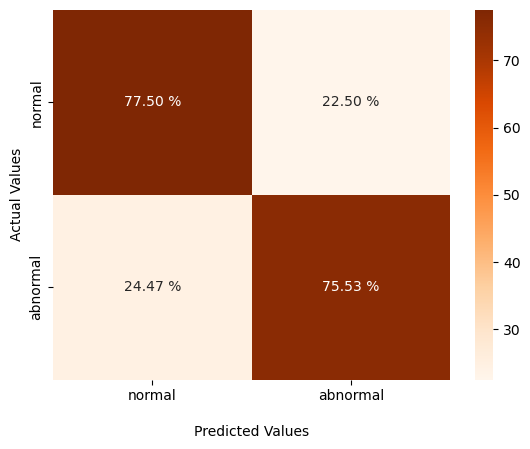

In [13]:
cmat = confusion_matrix(label_list, preds_list, normalize = 'true')

# Invert the values of the confusion matrix.
tn, fp, fn, tp = cmat.ravel()
cmat = np.array([[tp, fn], [fp, tn]])
cmat_rounded = np.round(cmat, decimals=4)

# Create visualization

ax = sns.heatmap(cmat_rounded*100, annot=True, cmap='Oranges',  fmt='.2f')

for t in ax.texts:
    t.set_text(t.get_text() + " %")

# Change X and Y axis labels to match the reversed order of the classes.
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values')
ax.xaxis.set_ticklabels(['normal', 'abnormal'])
ax.yaxis.set_ticklabels(['normal', 'abnormal'])

# Show results
plt.show()

In [14]:
tn, fp, fn, tp = confusion_matrix(label_list, preds_list).ravel()
print('True Negative(TN)=  %s\nFalse Positive(FP)= %s\nFalse Negative(FN)= %s\nTrue Positive(TP)=  %s' % (tn, fp, fn,tp))

True Negative(TN)=  2287
False Positive(FP)= 741
False Negative(FN)= 703
True Positive(TP)=  2422


### Plot ROC-Curve and calculate AUC

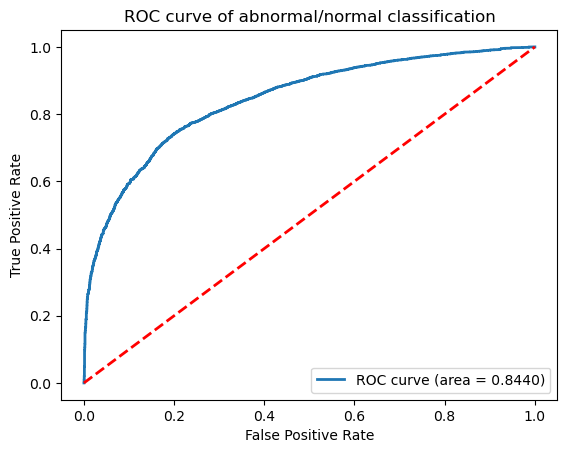

In [15]:
fpr, tpr, threshold = metrics.roc_curve(np.array(label_list), np.array(output_list))
#ROC CURVE
plt.figure()
plt.plot(fpr, tpr, lw=2, label='ROC curve (area = %0.4f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve of abnormal/normal classification')
plt.legend(loc="lower right")
plt.show()

In [16]:
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = threshold[optimal_idx]
print("Optimal threshold:", optimal_threshold)

Optimal threshold: 0.18638910353183746
